# Проверка базовых вариантов: новости → «бак» → рынок

**Модель, которую проверяем**

$$x_{t+1}=A\,x_t+\varepsilon_t,\qquad y_t=\langle g,x_t\rangle,\qquad A\ \text{— сжимающая}$$

* $\varepsilon_t$ — «что принесли новости дня $t$» (набор чисел);
* $x_t$ — «бак»: накопленное настроение, которое со временем забывается;
* $y_t$ — то, что мы хотим объяснить на рынке (величина дневного хода, доходность).

**Главный вопрос тетрадки:** *дают ли новости что-то сверх того, что уже известно из самой истории рынка?*
Это важнее, чем «R² больше нуля»: волатильность и так сама себя предсказывает, и любой новостной признак
сначала надо сравнить с этим.

**Ход работы**

| № | Блок | Зачем |
|---|------|-------|
| 1 | Настройки и инструменты | общие функции: «бак», регрессия, метрики |
| 2 | Проверка на синтетике | убедиться, что метод вообще умеет находить сигнал |
| 3 | Загрузка данных | берём готовый датасет |
| 4 | Аудит данных | найти места, где данные могут обмануть |
| 5 | Что предсказываем | цели: величина хода и доходность |
| 6 | Эмбеддинги $\varepsilon_t$ | три простых способа превратить новости в числа |
| 7 | Бак $x_t$ | как работает память |
| 8 | Основной эксперимент | бейзлайны против моделей с новостями |
| 9 | Другие цели | сработает ли на знаке доходности |
| 10 | Диагональная $A$ | у каждой компоненты своя скорость забывания |
| 11 | Форма памяти | действительно ли след новости спадает экспоненциально |
| 12 | Плацебо | не получили ли мы результат случайно |
| 13 | Walk-forward | устойчив ли результат по годам |
| 14 | Сводка | итог и как его читать |

## 1. Настройки и инструменты

Здесь только общие функции. Главная идея — **«бак с дыркой»**: каждый день в бак доливают новости,
а старые новости понемногу забываются. Скорость забывания задаём **периодом полураспада** (в календарных днях):
через столько дней вклад новости уменьшается вдвое. `0` — памяти нет, учитывается только сегодняшний день.

Забывание считается по **календарным дням**: за выходные (3 дня) бак забывает сильнее, чем за обычные сутки.

In [1]:
import re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.decomposition import TruncatedSVD
from scipy.stats import spearmanr, norm

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "figure.figsize": (11, 4)})

# ---------- настройки (можно менять) ----------
TRAIN_END  = "2016-12-31"          # обучение:   начало → 2016
VAL_END    = "2019-12-31"          # валидация:  2017–2019 (здесь выбираем параметры)
                                   # тест:       2020 → конец (смотрим один раз)
TARGET_TICKER = "^GSPC"
HALF_LIVES = [0, 1, 3, 7, 14, 30, 60]   # периоды полураспада, календарные дни (0 = нет памяти)
ALPHAS     = [1, 10, 100, 1000]         # сила ridge-штрафа (чем больше, тем «осторожнее» модель)
D_TFIDF    = 5                          # размерность ε_t в варианте TF-IDF
Z_WINDOW   = 252                        # окно для «очистки» признаков от тренда (≈ 1 год)
WARMUP     = 260                        # первые дни не используем: признаки ещё «разогреваются»
N_PLACEBO  = 100                        # число случайных перестановок в плацебо-тесте
SEED = 0

In [3]:
# ---------- бак ----------
def decay_factors(gap_days, half_life):
    """Во сколько раз бак «забывает» за gap_days календарных дней. half_life — число или вектор."""
    hl = np.atleast_1d(np.asarray(half_life, dtype=float))
    g = np.asarray(gap_days, dtype=float)[:, None]
    safe = np.where(hl > 0, hl, 1.0)
    return np.where(hl > 0, 0.5 ** (g / safe), 0.0)           # форма (T, 1) или (T, d)

def ou_state(eps, gap_days, half_life):
    """x_t = забывание · x_{t-1} + ε_t   (это и есть x_{t+1} = A x_t + ε_t при A = диагональная)."""
    E = np.nan_to_num(np.asarray(eps, dtype=float))
    dec = decay_factors(gap_days, half_life)
    X = np.zeros_like(E)
    prev = np.zeros(E.shape[1])
    for t in range(len(E)):
        prev = dec[t] * prev + E[t]
        X[t] = prev
    return X

def shift_rows(X, k):
    """Сдвиг вниз на k строк: для k=1 строка t получает значение дня t-1 (новости вчера → цель сегодня)."""
    X = np.asarray(X, dtype=float)
    if k == 0:
        return X
    out = np.full_like(X, np.nan)
    out[k:] = X[:-k]
    return out

# ---------- регрессия ----------
def fit_ridge(F, y, train_mask, alpha):
    """Обучаем линейную модель (ridge) на train и возвращаем функцию-предсказатель."""
    sc = StandardScaler().fit(F[train_mask])
    m = Ridge(alpha=alpha).fit(sc.transform(F[train_mask]), y[train_mask])
    return lambda Z: m.predict(sc.transform(Z))

def predict_all(F, y, ok, train_mask, alpha):
    pred = np.full(len(y), np.nan)
    pred[ok] = fit_ridge(F, y, train_mask & ok, alpha)(F[ok])
    return pred

# ---------- метрики ----------
def r2_vs_mean(y, yhat, mask, ref):
    """R² относительно «всегда предсказывать среднее по train». 0 = не лучше среднего, <0 = хуже."""
    return 1 - np.sum((y[mask] - yhat[mask]) ** 2) / np.sum((y[mask] - ref) ** 2)

def gain_vs_base(y, yhat_new, yhat_base, mask):
    """На сколько % ошибка (MSE) новой модели меньше, чем у базовой. >0 = новая лучше."""
    return 100 * (1 - np.mean((y[mask] - yhat_new[mask]) ** 2) / np.mean((y[mask] - yhat_base[mask]) ** 2))

def hac_cov(Xm, resid, lags):
    """Ошибки оценок с поправкой на автокорреляцию (Ньюи–Уэст): обычные p-value здесь слишком оптимистичны."""
    n = len(resid); Xe = Xm * resid[:, None]
    S = Xe.T @ Xe / n
    for l in range(1, lags + 1):
        G = Xe[l:].T @ Xe[:-l] / n
        S += (1 - l / (lags + 1)) * (G + G.T)
    Qi = np.linalg.inv(Xm.T @ Xm / n)
    return Qi @ S @ Qi / n

def ols_hac(X, y, lags=10):
    Xm = np.column_stack([np.ones(len(y)), X])
    beta = np.linalg.lstsq(Xm, y, rcond=None)[0]
    se = np.sqrt(np.diag(hac_cov(Xm, y - Xm @ beta, lags)))
    return beta, se

def clark_west(y, yhat_base, yhat_new, lags=10):
    """Тест «новая модель значимо лучше базовой?» (Кларк–Уэст, для вложенных моделей). Возвращает t и p (односторонний)."""
    f = (y - yhat_base) ** 2 - ((y - yhat_new) ** 2 - (yhat_base - yhat_new) ** 2)
    b, se = ols_hac(np.empty((len(f), 0)), f, lags)
    t = b[0] / se[0]
    return t, 1 - norm.cdf(t)

def select_on_val(make_F, y, ok, train, val, half_lives, alphas):
    """Перебираем период полураспада и alpha; выбираем лучшие по ошибке на валидации."""
    best = None
    for h in half_lives:
        F = make_F(h)
        for a in alphas:
            yh = predict_all(F, y, ok, train, a)
            mse = np.mean((y[val & ok] - yh[val & ok]) ** 2)
            if best is None or mse < best["val_mse"]:
                best = dict(half_life=h, alpha=a, val_mse=mse)
    return best

## 2. Проверка на синтетике: умеет ли метод находить сигнал?

Прежде чем смотреть на реальные данные, проверим сам метод на **искусственных**, где ответ известен.

Что делаем:
1. Генерируем случайные «новости» $\varepsilon_t$.
2. Прогоняем через бак с **известным** периодом полураспада = 7 дней.
3. Делаем «цель» = сигнал бака + шум. Параметр `share` — какая доля разброса цели объясняется сигналом.
4. Пробуем разные периоды полураспада и смотрим, находит ли метод правильный (7 дней).

Зачем: на реальном рынке сигнал слабый (доли процента). Если на таком уровне шума метод *не способен* найти
известный ответ, то «ничего не нашли» в реальных данных будет означать лишь «не хватило мощности», а не «сигнала нет».

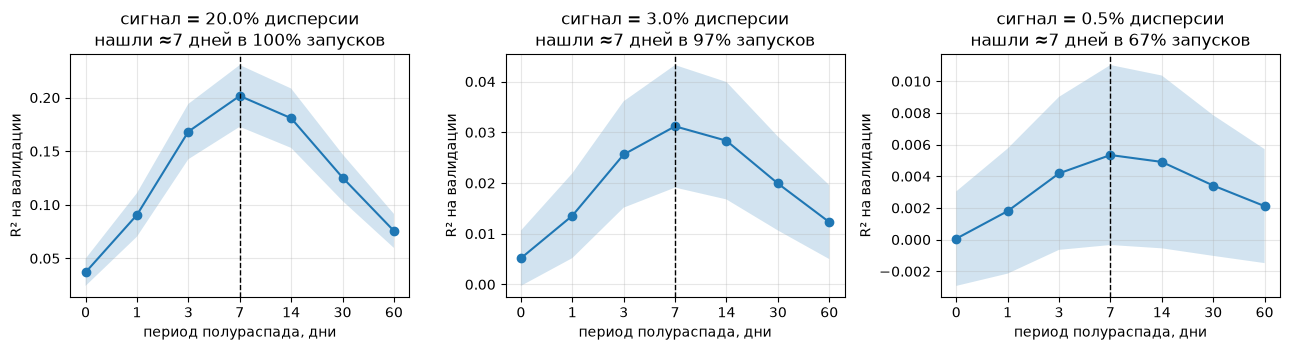

In [4]:
def synthetic_run(share, seed, n=5000, d=3, true_hl=7):
    rng = np.random.default_rng(seed)
    eps = rng.standard_normal((n, d))
    gap = np.ones(n)
    s = ou_state(eps, gap, true_hl) @ rng.standard_normal(d)
    s = (s - s.mean()) / s.std()
    y = np.sqrt(share) * s + np.sqrt(1 - share) * rng.standard_normal(n)
    idx = np.arange(n)
    tr, va = idx < int(n * 0.85), idx >= int(n * 0.85)           # такая же пропорция train/val, как в реальных данных
    ok = np.ones(n, bool)
    scores = []
    for h in HALF_LIVES:
        yh = predict_all(ou_state(eps, gap, h), y, ok, tr, 10)
        scores.append(r2_vs_mean(y, yh, va, y[tr].mean()))
    return np.array(scores)

SHARES = [0.20, 0.03, 0.005]
res, hit = {}, {}
for sh in SHARES:
    runs = np.array([synthetic_run(sh, seed) for seed in range(30)])
    res[sh] = runs
    best_h = np.array(HALF_LIVES)[runs.argmax(axis=1)]
    hit[sh] = np.mean(np.isin(best_h, [3, 7, 14]))            # «попали» = нашли 3, 7 или 14 дней (рядом с истиной)

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, sh in zip(axs, SHARES):
    m, s = res[sh].mean(0), res[sh].std(0)
    xs = np.arange(len(HALF_LIVES))
    ax.plot(xs, m, marker="o"); ax.fill_between(xs, m - s, m + s, alpha=0.2)
    ax.axvline(HALF_LIVES.index(7), color="k", ls="--", lw=1)
    ax.set_xticks(xs); ax.set_xticklabels(HALF_LIVES)
    ax.set_title(f"сигнал = {sh:.1%} дисперсии\nнашли ≈7 дней в {hit[sh]:.0%} запусков")
    ax.set_xlabel("период полураспада, дни"); ax.set_ylabel("R² на валидации")
plt.tight_layout(); plt.show()

**Как читать.** Пунктир — истинный ответ (7 дней), линия — среднее по 30 случайным запускам, полоса — разброс.

* При сильном сигнале пик чётко на 7 днях — метод работает, код без ошибок.
* При слабом сигнале (как на реальном рынке) пик размывается, и часть запусков «промахивается».
  Это **предел чувствительности метода**: если на реальных данных сигнал такого же масштаба, то точное значение
  периода полураспада мы определить не сможем, и осторожнее надо относиться к «красивым» значениям λ.

## 3. Загрузка данных

Используем готовый датасет. Для модели достаточно:
* `daily` — одна строка на торговый день: число статей и склеенный текст финансовых новостей;
* `prices` — котировки (нужны high/low для оценки величины дневного хода);
* из `news` берём только несколько служебных колонок — для аудита.

In [5]:
from scripts.build_dataset import ensure_dataset

paths = ensure_dataset()
daily = pd.read_parquet(paths["daily"])
daily["date"] = pd.to_datetime(daily["date"])
daily = daily.sort_values("date").reset_index(drop=True)
prices = pd.read_parquet(paths["prices"])
news_meta = pd.read_parquet(paths["news"], columns=["pub_time_utc", "trading_date", "is_finance", "flag_source"])

dates = pd.DatetimeIndex(daily["date"])
gap_days = dates.to_series().diff().dt.days.fillna(1).to_numpy()     # сколько календарных дней прошло с прошлой торговой сессии
masks = {"train": np.asarray(dates <= TRAIN_END),
         "val":   np.asarray((dates > TRAIN_END) & (dates <= VAL_END)),
         "test":  np.asarray(dates > VAL_END)}

print(f"{dates[0].date()} → {dates[-1].date()}, {len(dates)} торговых дней")
for k, m in masks.items():
    print(f"  {k:5s} {dates[m][0].date()} → {dates[m][-1].date()}  n={m.sum()}")
print("Пауза между сессиями (календарных дней):", dict(pd.Series(gap_days).value_counts().head(4)))

14:18:40 INFO scripts.build_dataset: processed files exist but do not cover 1990-01-01 -> today; rebuilding
14:18:46 INFO scripts.news: HF mirror 1990: 98905 articles, 12 month(s) where the Kaggle mirror is short
14:18:49 INFO scripts.news: HF mirror 1991: 85588 articles, 12 month(s) where the Kaggle mirror is short


14:18:49 WARNING huggingface_hub.utils._http: Warning: You are sending unauthenticated requests to the HF Hub. Please set a HF_TOKEN to enable higher rate limits and faster downloads.
14:18:51 INFO scripts.news: HF mirror 1992: 86038 articles, 12 month(s) where the Kaggle mirror is short
14:18:53 INFO scripts.news: HF mirror 1993: 82020 articles, 12 month(s) where the Kaggle mirror is short
14:18:56 INFO scripts.news: HF mirror 1994: 79456 articles, 12 month(s) where the Kaggle mirror is short
14:18:58 INFO scripts.news: HF mirror 1995: 85235 articles, 12 month(s) where the Kaggle mirror is short
14:19:00 INFO scripts.news: HF mirror 1996: 79789 articles, 12 month(s) where the Kaggle mirror is short
14:19:02 INFO scripts.news: HF mirror 1997: 90018 articles, 12 month(s) where the Kaggle mirror is short
14:19:05 INFO scripts.news: HF mirror 1998: 94244 articles, 12 month(s) where the Kaggle mirror is short
14:19:07 INFO scripts.news: HF mirror 1999: 96261 articles, 12 month(s) where the

KeyboardInterrupt: 

## 4. Аудит данных: где нас могут обмануть

Перед моделированием смотрим на три вещи, которые известны как источники ложных результатов:

1. **Объём новостей сильно менялся** (финансовых статей в день было ~77, стало ~20). Если подать в модель сырой объём,
   она «увидит» медленный тренд, а не информацию. Поэтому признаки ниже очищаем скользящим z-score.
2. **До 2007 года у статей только дата**, без времени (полночь по Нью-Йорку). Тогда «новости дня» — это вчерашние события
   в утренней газете, а позже — статьи, написанные в течение самого торгового дня (в том числе **о самом ходе рынка**).
   Смысл связи «новость ↔ рынок» в этих двух эпохах разный.
3. **С 2023 года флаги `is_finance` восстановлены классификатором**, а не взяты из метаданных. Отбор «финансовых» статей там шумнее.

In [ ]:
nm = news_meta.copy()
nm["year"] = pd.to_datetime(nm["trading_date"]).dt.year
ts = pd.to_datetime(nm["pub_time_utc"], utc=True)
midnight = (ts.dt.minute == 0) & (ts.dt.second == 0) & ts.dt.hour.isin([4, 5])     # «полночь по Нью-Йорку» = в датасете только дата

yr = daily["date"].dt.year
audit = pd.DataFrame({
    "фин. статей в день": daily.groupby(yr)["n_finance"].mean().round(1),
    "доля статей без времени": midnight.groupby(nm["year"]).mean().round(2),
    "доля флагов от классификатора": (nm["flag_source"] == "text_model").groupby(nm["year"]).mean().round(2),
})
audit.index.name = "год"
display(audit.T)

fig, ax = plt.subplots(figsize=(11, 3.2))
audit["фин. статей в день"].plot(ax=ax, marker="o", label="финансовых статей в день")
ax2 = ax.twinx(); ax2.grid(False)
audit["доля статей без времени"].plot(ax=ax2, color="C1", marker=".", label="без времени (правая ось)")
audit["доля флагов от классификатора"].plot(ax=ax2, color="C3", marker=".", label="флаги классификатора (правая ось)")
ax.set_ylabel("статей в день"); ax2.set_ylabel("доля"); fig.legend(loc="upper right", bbox_to_anchor=(0.9, 0.9))
plt.tight_layout(); plt.show()

**Выводы для дизайна эксперимента:**
* признаки «по объёму» приводим к *в день на календарные сутки* и очищаем z-score по прошлому году;
* результаты **всегда смотрим по периодам** (до/после 2007, до/после 2023), а не только одним числом;
* «тот же день» ($\varepsilon_t\to y_t$) — это скорее **объяснение**, чем прогноз, а «следующий день» ($\varepsilon_t\to y_{t+1}$) — честный прогноз.
  Поэтому оба варианта считаем рядом.

## 5. Что предсказываем

Три цели для индекса S&P 500. Все — на дневной частоте:

| Цель | Что это | Почему |
|---|---|---|
| `log_range` | $\ln(\text{High}/\text{Low})$ за день (логарифм) | размах дня — **основной вариант**: менее шумная мера «величины хода», чем |доходность| |
| `log_abs` | $\ln\lvert r_t\rvert$ | простой вариант, как в исходной тетрадке |
| `ret` | доходность $r_t$, в % | знак/направление; ожидаем, что предсказать почти нельзя |

Берём **логарифм** для величин хода: сырые значения имеют тяжёлые хвосты (2008, 2020), и несколько дней доминировали бы в ошибке.

In [ ]:
px = (prices[prices["ticker"] == TARGET_TICKER].assign(date=lambda d: pd.to_datetime(d["date"]))
      .set_index("date").sort_index().reindex(dates))
ret = 100 * np.log(px["adj_close"]).diff()
rng_ = np.log(px["high"] / px["low"]).where(px["high"] > px["low"])

TARGETS = {
    "log_range": np.log(rng_.clip(lower=1e-4)),
    "log_abs":   np.log(ret.abs().clip(lower=1e-3)),
    "ret":       ret,
}
for k, v in TARGETS.items():
    print(f"{k:10s} непустых значений: {v.notna().sum()}   среднее {v.mean():+.3f}   ст.откл. {v.std():.3f}")

# автокорреляция: «помнит ли цель вчерашний день?»
lags = range(1, 61)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.2), sharey=True)
for ax, k in zip(axs, ["log_range", "ret"]):
    ax.bar(list(lags), [TARGETS[k].autocorr(l) for l in lags], color="C0")
    ax.set_title(f"автокорреляция: {k}"); ax.set_xlabel("лаг, дни")
axs[0].set_ylabel("корреляция")
plt.tight_layout(); plt.show()

**Что видим.** У размаха дня автокорреляция высокая и спадает медленно: *волатильность помнит прошлое*
(за бурным днём чаще идёт бурный). У доходности корреляция около нуля: вчерашний день ничего не говорит о завтрашнем знаке.

**Следствие:** модель с новостями нужно сравнивать не с «средним», а с моделью, которая знает недавнюю историю цели.
Иначе любой признак, просто коррелирующий с уровнем волатильности, покажется «полезным».

## 6. Эмбеддинги $\varepsilon_t$: три простых способа превратить новости в числа

Эмбеддинг — это способ записать новости дня несколькими числами. Берём три способа, от самого простого:

| Название | Что считаем | Размерность | Что проверяет |
|---|---|---|---|
| `volume` | сколько статей в день | 2 | «дело в объёме новостей, а не в смысле?» |
| `lexicon` | доля слов «негатива», «позитива», «неопределённости» | 3 | простой смысл по словарю |
| `tfidf` | TF-IDF + сжатие (SVD) до 5 чисел | 5 | «о чём» пишут, без заранее заданного словаря |

`volume` — **контрольный** вариант. Если сложные эмбеддинги не лучше простого подсчёта статей, значит, они ловят только «шумность дня».

Для всех вариантов:
* всё, что обучается (TF-IDF, SVD), обучается **только на train**;
* затем каждый признак очищается: из него вычитается среднее за **прошлый** год и он делится на прошлогоднее ст. отклонение
  (так убираем тренд объёма и смену стиля источников, не заглядывая в будущее).

In [ ]:
texts = daily["finance_text"].fillna("")

# --- volume: статей в день на календарные сутки (чтобы понедельник не казался «больше»)
raw_volume = pd.DataFrame({
    "log_n_all": np.log1p(daily["n_articles"].to_numpy() / gap_days),
    "log_n_fin": np.log1p(daily["n_finance"].to_numpy() / gap_days),
}, index=dates)

# --- lexicon: упрощённый словарь (для серьёзной работы — словарь Loughran–McDonald)
NEG = """loss losses lose losing fall falls fell falling drop drops dropped decline declines declined plunge plunged plunges
slump slumped crash crisis fear fears worry worries worried recession default defaults bankruptcy bankrupt layoffs cuts weak
weakness slowdown downturn selloff turmoil panic collapse fail failed failure threat threatens trouble troubled fraud
debt deficit inflation unemployment""".split()
POS = """gain gains gained rise rises rose rising rally rallied surge surged jump jumped growth grow grew strong strength
recovery recover rebound boost improve improved improvement profit profits profitable record optimism optimistic upbeat beat""".split()
UNC = """uncertain uncertainty unclear volatile volatility may might could possibly unsettled doubt doubts concern concerns
concerned unpredictable turbulence risk risks risky""".split()

vocab = sorted(set(NEG + POS + UNC))
cnt = CountVectorizer(vocabulary=vocab, lowercase=True, token_pattern=r"(?u)\b\w+\b").transform(texts)
col = {w: i for i, w in enumerate(vocab)}
n_words = texts.str.split().str.len().clip(lower=1).to_numpy()
def rate(words):                                            # слов группы на 1000 слов текста
    return 1000 * np.asarray(cnt[:, [col[w] for w in set(words)]].sum(axis=1)).ravel() / n_words
raw_lex = pd.DataFrame({"neg_rate": rate(NEG), "pos_rate": rate(POS), "unc_rate": rate(UNC)}, index=dates)

# --- tfidf + SVD (обучаем только на train)
tr_idx = np.where(masks["train"])[0]
tfidf = TfidfVectorizer(min_df=5, max_df=0.5, max_features=20000, sublinear_tf=True, stop_words="english").fit(texts.iloc[tr_idx])
Xs = tfidf.transform(texts)
svd = TruncatedSVD(n_components=D_TFIDF, random_state=SEED).fit(Xs[tr_idx])
raw_tfidf = pd.DataFrame(svd.transform(Xs), index=dates, columns=[f"svd{i+1}" for i in range(D_TFIDF)])

# --- очистка: z-score по прошлому году (без заглядывания в будущее)
def past_zscore(df, window=Z_WINDOW, minp=60, clip=5):
    mu = df.rolling(window, min_periods=minp).mean().shift(1)
    sd = df.rolling(window, min_periods=minp).std().shift(1)
    return ((df - mu) / sd).clip(-clip, clip).fillna(0.0)

EMB = {"volume": past_zscore(raw_volume), "lexicon": past_zscore(raw_lex), "tfidf": past_zscore(raw_tfidf)}
for k, v in EMB.items():
    print(f"{k:8s} ε_t: {v.shape[1]} числа(ел) на день   колонки: {list(v.columns)}")

# «первый взгляд»: корреляция признаков с размахом дня (на train, тот же день)
yy = TARGETS["log_range"]
quick = pd.concat({k: v.apply(lambda c: c[masks["train"]].corr(yy[masks["train"]])) for k, v in EMB.items()})
print("\nКорреляция признака с log_range (train, тот же день):")
display(quick.round(3).to_frame("corr").T)

**Что видим.** Это первичный взгляд на то, какие признаки вообще связаны с величиной хода в тот же день.
Корреляция «в тот же день» — не прогноз: статьи, вышедшие в сам день движения, могут просто описывать его. Прогнозную силу покажет только вариант «следующий день» ниже.

## 7. Бак $x_t$: как работает память

Берём ε_t и пропускаем через бак: $x_t = \text{забывание}\cdot x_{t-1}+\varepsilon_t$.
Ниже — один и тот же признак (негативность слов) при разной памяти. Чем длиннее память, тем глаже кривая и дольше «шлейф» после всплеска.

In [ ]:
STATE = {}                                                   # кэш: (эмбеддинг, период) → состояние бака
def get_state(emb, h):
    if (emb, h) not in STATE:
        STATE[(emb, h)] = ou_state(EMB[emb].to_numpy(), gap_days, h)
    return STATE[(emb, h)]

j = list(EMB["lexicon"].columns).index("neg_rate")
sel = (dates >= "2020-01-01") & (dates <= "2020-06-30")
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(dates[sel], EMB["lexicon"]["neg_rate"].to_numpy()[sel], color="0.7", lw=1, label="ε_t (сырой признак)")
for h in (1, 7, 30):
    ax.plot(dates[sel], get_state("lexicon", h)[sel, j], label=f"x_t, полураспад {h} дн.")
ax.set_title("Негативность новостей: сам признак и «бак» с разной памятью (2020, начало пандемии)")
ax.legend(ncol=2); plt.tight_layout(); plt.show()

## 8. Основной эксперимент: бейзлайны против моделей с новостями

**Лестница сравнения** (каждая следующая ступень знает чуть больше):

| Модель | Что знает |
|---|---|
| `mean` | только среднее по train — «ничего не знаю» |
| `last` | вчерашнее значение цели |
| `EWMA(y)` | «бак» с самой целью внутри: экспоненциально сглаженное прошлое цели |
| `HAR` | цель за последний 1, 5 и 22 дня — классический сильный бейзлайн для волатильности |
| `новости` | только бак с новостями (без истории цели) |
| `HAR + новости` | **главный вопрос**: даёт ли бак что-то сверх HAR? |

**Как сравниваем.** Параметры (период полураспада, сила штрафа) выбираем на валидации (2017–2019),
итог смотрим на тесте (2020 и позже), к которому при подборе не обращались.

Таблица читается так:
* `R² val/test` — доля разброса, объяснённая моделью, относительно «среднего по train»; ≤0 = не лучше среднего;
* `Δ MSE vs HAR, %` — на сколько процентов ошибка меньше, чем у HAR; **>0 хорошо**;
* `CW p` — p-value теста Кларка–Уэста («новые признаки значимо улучшают HAR?»); маленькое = улучшение не случайно;
* `IC test` — ранговая корреляция прогноза и факта.

Два режима по времени:
* **same_day:** новости дня $t$ → цель дня $t$ (объяснение);
* **next_day:** новости дня $t$ → цель дня $t+1$ (прогноз).

In [ ]:
TIMINGS = {"same_day": 0, "next_day": 1}

def har_features(y_ser):
    y1 = y_ser.shift(1)                                      # только то, что известно ДО дня цели
    return pd.DataFrame({"lag1": y1, "avg5": y1.rolling(5).mean(), "avg22": y1.rolling(22).mean()})

def build_case(y_ser):
    y = y_ser.to_numpy(float)
    har = har_features(y_ser).to_numpy()
    ok = np.isfinite(y) & np.isfinite(har).all(axis=1) & (np.arange(len(y)) >= WARMUP)
    return y, har, ok

def evaluate_case(y_ser, shift, emb_names=("volume", "lexicon", "tfidf")):
    y, har, ok = build_case(y_ser)
    tr, va = masks["train"], masks["val"]
    m_va, m_te = va & ok, masks["test"] & ok
    ref = y[tr & ok].mean()

    P, INFO = {}, {}
    P["mean"] = np.where(ok, ref, np.nan)
    P["last"] = np.where(ok, har[:, 0], np.nan)
    P["HAR"] = predict_all(har, y, ok, tr, 1.0)

    # EWMA(y): «бак», в который доливается сама цель; период подбираем на валидации
    ew = lambda h: y_ser.shift(1).ewm(halflife=h).mean().to_numpy()[:, None]
    INFO["EWMA(y)"] = select_on_val(ew, y, ok, tr, va, [1, 3, 7, 14, 30], [1.0])
    P["EWMA(y)"] = predict_all(ew(INFO["EWMA(y)"]["half_life"]), y, ok, tr, 1.0)

    for emb in emb_names:
        news = lambda h, emb=emb: shift_rows(get_state(emb, h), shift)
        INFO[f"новости: {emb}"] = b1 = select_on_val(news, y, ok, tr, va, HALF_LIVES, ALPHAS)
        P[f"новости: {emb}"] = predict_all(news(b1["half_life"]), y, ok, tr, b1["alpha"])
        both = lambda h, news=news: np.hstack([har, news(h)])
        INFO[f"HAR + {emb}"] = b2 = select_on_val(both, y, ok, tr, va, HALF_LIVES, ALPHAS)
        P[f"HAR + {emb}"] = predict_all(both(b2["half_life"]), y, ok, tr, b2["alpha"])

    rows = []
    for name, yh in P.items():
        r = {"модель": name,
             "полураспад": INFO.get(name, {}).get("half_life", ""),
             "alpha": INFO.get(name, {}).get("alpha", ""),
             "R² val": r2_vs_mean(y, yh, m_va, ref), "R² test": r2_vs_mean(y, yh, m_te, ref),
             "IC test": spearmanr(yh[m_te], y[m_te])[0] if np.std(yh[m_te]) > 0 else np.nan}
        if name.startswith("HAR + "):
            r["Δ MSE vs HAR, %"] = gain_vs_base(y, yh, P["HAR"], m_te)
            r["CW p"] = clark_west(y[m_te], P["HAR"][m_te], yh[m_te])[1]
        rows.append(r)
    return pd.DataFrame(rows).set_index("модель"), P, INFO, (y, har, ok)

CASES = {}                                                   # сохраняем для следующих блоков
tables = {}
for tname, shift in TIMINGS.items():
    tab, P, INFO, data = evaluate_case(TARGETS["log_range"], shift)
    CASES[("log_range", tname)] = dict(P=P, INFO=INFO, data=data, shift=shift)
    tables[tname] = tab
    print(f"\n===== цель log_range, режим {tname} =====")
    display(tab.round(4))

**Как интерпретировать (читай сверху вниз):**
1. `HAR` должен заметно бить `mean` и `last`: это подтверждает, что волатильность предсказуема по её истории.
2. `новости: ...` без истории цели — если R² >0, новости *что-то* объясняют, но это может быть то же самое, что уже знает HAR.
3. **`HAR + ...` против `HAR`** — главная проверка. Смотрим на `Δ MSE vs HAR` и `CW p`:
   прирост в доли процента и p > 0.1 — новости ничего не добавили.
4. Сравнение `volume` с `lexicon` и `tfidf`: если «просто число статей» не хуже, то «смысл» новостей не нужен.
5. Сравнение `same_day` и `next_day`: большой разрыв — новости скорее *сопровождают* ход, чем предсказывают его.

## 9. Другие цели: сработает ли на знаке доходности?

Те же шаги для двух других целей: `log_abs` и `ret` (доходность со знаком).
Ожидание из теории: на `ret` ничего не получится (рынок быстро учитывает новости), а на величинах хода — максимум небольшая добавка.
Показываем только главное: **прирост к HAR** на тесте.

In [ ]:
rows = []
for target in ["log_abs", "ret"]:
    for tname, shift in TIMINGS.items():
        tab, P, INFO, data = evaluate_case(TARGETS[target], shift)
        CASES[(target, tname)] = dict(P=P, INFO=INFO, data=data, shift=shift)
        for emb in ("volume", "lexicon", "tfidf"):
            r = tab.loc[f"HAR + {emb}"]
            rows.append({"цель": target, "режим": tname, "эмбеддинг": emb,
                         "R² test (HAR)": tab.loc["HAR", "R² test"], "R² test (HAR+новости)": r["R² test"],
                         "Δ MSE vs HAR, %": r["Δ MSE vs HAR, %"], "CW p": r["CW p"]})
display(pd.DataFrame(rows).set_index(["цель", "режим", "эмбеддинг"]).round(4))

## 10. Диагональная $A$: у каждой компоненты своя скорость забывания

До сих пор все компоненты $\varepsilon_t$ забывались с одной скоростью ($A=\lambda I$).
Логично, что «негатив» и «неопределённость» могут жить в памяти по-разному.
Допустим, у каждой компоненты $i$ свой период полураспада — это **диагональная $A$**.

Подбираем периоды покоординатно на валидации (по очереди улучшаем каждую компоненту, два прохода).
Опасность: параметров стало больше, а валидация короткая — так что ждём в основном переобучения, и смотрим на тест.

In [ ]:
COMP = {}                                                    # кэш состояний отдельных компонент
def comp_state(emb, j, h):
    if (emb, j, h) not in COMP:
        COMP[(emb, j, h)] = ou_state(EMB[emb].to_numpy()[:, [j]], gap_days, h)
    return COMP[(emb, j, h)]

def diag_matrix(emb, hl_vec, shift):
    return shift_rows(np.hstack([comp_state(emb, j, h) for j, h in enumerate(hl_vec)]), shift)

def fit_diagonal(emb, case, passes=2):
    y, har, ok = case["data"]; shift = case["shift"]
    alpha = case["INFO"][f"HAR + {emb}"]["alpha"]
    tr, va = masks["train"], masks["val"]
    d = EMB[emb].shape[1]
    hl = [case["INFO"][f"HAR + {emb}"]["half_life"]] * d       # старт: найденное общее значение
    def val_mse(vec):
        F = np.hstack([har, diag_matrix(emb, vec, shift)])
        yh = predict_all(F, y, ok, tr, alpha)
        return np.mean((y[va & ok] - yh[va & ok]) ** 2)
    for _ in range(passes):
        for j in range(d):
            scores = {h: val_mse(hl[:j] + [h] + hl[j + 1:]) for h in HALF_LIVES}
            hl[j] = min(scores, key=scores.get)
    F = np.hstack([har, diag_matrix(emb, hl, shift)])
    return hl, alpha, predict_all(F, y, ok, tr, alpha)

rows = []
for tname in TIMINGS:
    case = CASES[("log_range", tname)]
    y, har, ok = case["data"]; m_te = masks["test"] & ok
    for emb in ("volume", "lexicon", "tfidf"):
        hl, alpha, yh = fit_diagonal(emb, case)
        yh_scalar = case["P"][f"HAR + {emb}"]
        rows.append({"режим": tname, "эмбеддинг": emb,
                     "полураспады по компонентам": hl,
                     "Δ MSE vs HAR: общий λ, %": gain_vs_base(y, yh_scalar, case["P"]["HAR"], m_te),
                     "Δ MSE vs HAR: диагональная A, %": gain_vs_base(y, yh, case["P"]["HAR"], m_te),
                     "CW p (диагональная)": clark_west(y[m_te], case["P"]["HAR"][m_te], yh[m_te])[1]})
display(pd.DataFrame(rows).set_index(["режим", "эмбеддинг"]).round(4))

**Как читать.** Если диагональная $A$ не лучше общего $\lambda$ на **тесте**, усложнение не оправдано.
Полная матрица $A$ (компоненты влияют друг на друга) — следующий шаг, и только если этот даст выигрыш.

## 11. Форма памяти: действительно ли след новости спадает экспоненциально?

Это прямая проверка самой идеи «бака». Не предполагая никакой формы памяти, оцениваем свободную регрессию:

$$y_t = \text{HAR} + h_0\,\varepsilon_t + h_1\,\varepsilon_{t-1} + \dots + h_{30}\,\varepsilon_{t-30}$$

и рисуем коэффициенты $h_k$ по $k$. Если модель с «баком» верна, $h_k$ должны **плавно спадать, как $0.5^{k/\text{период}}$**.

Возможные картины:
* плавный спад → память есть, идея бака оправдана;
* всплеск на $k=0$ и дальше ноль → памяти нет, достаточно $\lambda=0$;
* шум вокруг нуля → сигнала нет.

Серая полоса — 95% доверительный интервал (с поправкой на автокорреляцию). Красная кривая — лучшая экспонента.
Используем train+val (без теста).

In [ ]:
K = 30
IR_FEATURES = [("volume", "log_n_fin"), ("lexicon", "neg_rate"), ("tfidf", "svd1")]
y, har, ok = build_case(TARGETS["log_range"])
use = (masks["train"] | masks["val"]) & ok

fig, axs = plt.subplots(1, 3, figsize=(14, 3.6), sharex=True)
for ax, (emb, c) in zip(axs, IR_FEATURES):
    f = EMB[emb][c].to_numpy()
    L = np.column_stack([shift_rows(f[:, None], k).ravel() for k in range(K + 1)])
    rows_ok = use & np.isfinite(L).all(axis=1)
    beta, se = ols_hac(np.hstack([har[rows_ok], L[rows_ok]]), y[rows_ok], lags=K)
    h_, s_ = beta[1 + har.shape[1]:], se[1 + har.shape[1]:]
    ks = np.arange(K + 1)
    ax.fill_between(ks, h_ - 1.96 * s_, h_ + 1.96 * s_, color="0.8"); ax.plot(ks, h_, marker=".", color="C0")
    # лучшая экспонента a · 0.5^(k/h)
    best = min(((np.sum((h_ - ((b @ h_) / (b @ b)) * b) ** 2), hh, (b @ h_) / (b @ b))
                for hh in (1, 3, 7, 14, 30) for b in [0.5 ** (ks / hh)]), key=lambda t: t[0])
    ax.plot(ks, best[2] * 0.5 ** (ks / best[1]), color="C3", lw=1.5, label=f"экспонента, полураспад {best[1]} дн.")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(f"{emb}: {c}"); ax.set_xlabel("лаг k (дни назад)"); ax.legend(loc="upper right")
axs[0].set_ylabel("вклад h_k в log_range")
plt.tight_layout(); plt.show()

## 12. Плацебо: не получили ли мы результат случайно

Даже на чистом шуме среди десятков вариантов (эмбеддинги × периоды × alpha) что-то «выстрелит».
Проверяем честно: берём выбранную модель и **сдвигаем новости по времени на случайное число дней** — ломаем связь с рынком,
но сохраняем все свойства самих новостей (их автокорреляцию, объём, словарь).

Получаем распределение прироста к HAR **при отсутствии настоящей связи**. Если реальный прирост
не выделяется на его фоне — это не сигнал. $p$ — доля плацебо-прогонов, где прирост оказался не хуже реального.

In [ ]:
rng = np.random.default_rng(SEED)
PLACEBO = {}

def placebo(emb, tname, n=N_PLACEBO):
    case = CASES[("log_range", tname)]
    y, har, ok = case["data"]; shift = case["shift"]
    info = case["INFO"][f"HAR + {emb}"]
    m_te = masks["test"] & ok
    def gain(eps):
        x = shift_rows(ou_state(eps, gap_days, info["half_life"]), shift)
        yh = predict_all(np.hstack([har, x]), y, ok, masks["train"], info["alpha"])
        return gain_vs_base(y, yh, case["P"]["HAR"], m_te)
    real = gain(EMB[emb].to_numpy())
    shifts = rng.integers(60, len(y) - 60, size=n)
    fake = np.array([gain(np.roll(EMB[emb].to_numpy(), s, axis=0)) for s in shifts])
    return real, fake, (1 + np.sum(fake >= real)) / (n + 1)

fig, axs = plt.subplots(2, 3, figsize=(13, 6))
for i, tname in enumerate(TIMINGS):
    for j, emb in enumerate(("volume", "lexicon", "tfidf")):
        real, fake, p = placebo(emb, tname)
        PLACEBO[(emb, tname)] = p
        ax = axs[i, j]
        ax.hist(fake, bins=20, color="0.7"); ax.axvline(real, color="C3", lw=2)
        ax.set_title(f"{emb}, {tname}\nреальный прирост {real:+.2f}%,  p = {p:.2f}")
        ax.set_xlabel("прирост к HAR, % MSE")
plt.tight_layout(); plt.show()

**Как читать.** Серая гистограмма — «что получается при случайной связи»; красная линия — реальный результат.
Красная линия *правее* почти всей серой массы ($p<0.05$) — связь настоящая. Внутри серой массы — совпадение.

## 13. Walk-forward: устойчив ли результат по годам

Одно разбиение train/val/test легко обмануть (например, тест с пандемией 2020 года). Поэтому для каждого года $Y$ с 2010-го:
* обучаем модель на **всех данных до** 1 января $Y$;
* предсказываем год $Y$;
* считаем, на сколько % ошибка модели «HAR + новости» меньше, чем у HAR.

Параметры (период, alpha) берём те, что выбраны в блоке 8 (небольшая утечка в сам выбор параметров — оговорка).
Хороший результат — прирост **положителен в большинстве лет**, а не набран за один год.

In [ ]:
def walk_forward(emb, tname, first_year=2010):
    case = CASES[("log_range", tname)]
    y, har, ok = case["data"]; shift = case["shift"]
    info = case["INFO"][f"HAR + {emb}"]
    F = np.hstack([har, shift_rows(get_state(emb, info["half_life"]), shift)])
    ph, pn = np.full(len(y), np.nan), np.full(len(y), np.nan)
    gains = {}
    for Y in range(first_year, dates[-1].year + 1):
        tr = np.asarray(dates < f"{Y}-01-01") & ok
        te = np.asarray(dates.year == Y) & ok
        if te.sum() < 50:
            continue
        ph[te] = fit_ridge(har, y, tr, 1.0)(har[te])
        pn[te] = fit_ridge(F, y, tr, info["alpha"])(F[te])
        gains[Y] = gain_vs_base(y, pn, ph, te)
    allm = np.isfinite(pn)
    t, p = clark_west(y[allm], ph[allm], pn[allm])
    return pd.Series(gains), p

WF = {}
fig, axs = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for ax, tname in zip(axs, TIMINGS):
    for emb in ("volume", "lexicon", "tfidf"):
        g, p = walk_forward(emb, tname)
        WF[(emb, tname)] = dict(mean_gain=g.mean(), share_pos=(g > 0).mean(), cw_p=p)
        ax.plot(g.index, g.values, marker="o", label=f"{emb} (p={p:.2f})")
    ax.axhline(0, color="k", lw=0.8)
    ax.axvline(2022.5, color="0.5", ls=":", lw=1); ax.text(2022.6, ax.get_ylim()[1] * 0.9, "флаги от\nклассиф.", fontsize=8, color="0.4")
    ax.set_title(f"прирост к HAR по годам, {tname}"); ax.set_xlabel("год"); ax.legend(fontsize=8)
axs[0].set_ylabel("Δ MSE vs HAR, %  (>0 — новости помогли)")
plt.tight_layout(); plt.show()

## 14. Сводка

Для главной цели (`log_range`) собираем итоги трёх проверок для каждого эмбеддинга и режима.

In [ ]:
rows = []
for tname in TIMINGS:
    tab = tables[tname]
    for emb in ("volume", "lexicon", "tfidf"):
        r = tab.loc[f"HAR + {emb}"]
        rows.append({"режим": tname, "эмбеддинг": emb,
                     "полураспад, дн.": r["полураспад"],
                     "прирост к HAR на тесте, %": r["Δ MSE vs HAR, %"], "CW p": r["CW p"],
                     "плацебо p": PLACEBO[(emb, tname)],
                     "walk-forward: средний прирост, %": WF[(emb, tname)]["mean_gain"],
                     "walk-forward: доля лет с приростом": WF[(emb, tname)]["share_pos"]})
summary = pd.DataFrame(rows).set_index(["режим", "эмбеддинг"])

def verdict(r):
    if r["прирост к HAR на тесте, %"] <= 0 or r["CW p"] > 0.1:
        return "новости ничего не добавляют"
    if r["плацебо p"] > 0.1 or r["walk-forward: доля лет с приростом"] < 0.6:
        return "слабый/неустойчивый след"
    return "есть устойчивая добавка"
summary["вывод"] = summary.apply(verdict, axis=1)
display(summary.round(3))

### Как читать итог

Добавка новостей считается **реальной**, только если выполнены все четыре условия сразу:
1. прирост к HAR на тесте положителен и `CW p` < 0.05;
2. плацебо-$p$ < 0.05 (результат не случаен);
3. прирост положителен в большинстве лет walk-forward (а не один «хороший» год);
4. эмбеддинги `lexicon`/`tfidf` лучше контрольного `volume` (иначе работает «число статей», а не смысл).

**Осторожно с множественными сравнениями.** В таблице 6 строк × несколько проверок. Даже при полном отсутствии сигнала
примерно в одной из двадцати проверок p окажется < 0.05 случайно. Одиночный «зелёный» результат ничего не доказывает;
доверять стоит только тому, что повторяется в разных проверках и годах.

Типичные картины и что они значат:

| Что видим | Что это значит |
|---|---|
| `same_day` заметно лучше `next_day` | новости *описывают* ход, а не предсказывают его |
| `volume` не хуже остальных | важен «шум дня», а не содержание |
| прирост пропадает после 2023 | сказывается смена источника флагов (классификатор) |
| на `ret` ничего нет | как и ожидается: направление рынка новостями не предсказать |
| диагональная $A$ не лучше общей $\lambda$ | усложнять матрицу $A$ пока рано |

### Что делать дальше (по приоритету)

1. **Чистый прогноз «до открытия».** Использовать только статьи, вышедшие до 09:30 ET (есть `pub_time_utc`), и цель — от открытия до закрытия. Это снимает вопрос «новость описывает ход или предшествует ему».
2. **Ключ NYT API.** Получить метаданные за 2023–2025 вместо классификатора и убрать неоднородность.
3. **Эмбеддинги сильнее:** SBERT/FinBERT вместо словаря и TF-IDF; темы из `keywords` (ФРС, нефть, война) как отдельные каналы.
4. **Полная матрица $A$** с ограничением на спектральный радиус (< 1), обучаемая градиентом, — только если шаг «диагональная $A$» дал выигрыш.
5. **Больше «наблюдений» вместо большего числа лет:** отдельные акции и секторные ETF одновременно (общие $g$ и $A$, сотни рядов вместо одного), доходность за вычетом рынка.
6. **Многомерный выход:** $y_t$ — вектор по нескольким инструментам, $g$ — матрица (возможно низкого ранга).